# Visualización de datos con Seaborn

En este ejercicio vamos a ampliar el ejercicios de peatones con más gráficosde la librería `Seaborn`.

Recuerda que trabajamos con el fichero .csv de la página del Portal de Datos Abiertos del Ayuntamiento de Madrid (https://datos.madrid.es/). Desde dicha página buscamos `peatones` y nos lleva a `Aforos de peatones y bicicletas` (https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas). Aquí tenemos que descargarnos el fichero csv de peatones correspondiente al año 2020
https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads.


## Carga de datos y exploración del dataframe

Después de descargarnos el fichero `300321-3-aforos-peatones-bicicletas-csv.csv` correspondiente al año 2020  de la web https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads, lo dejamos en nuestra carpeta llamada Data y lo importamos como un dataframe llamado df.

Lo primero que tenemos que hacer es ver el contenido del fichero con una aplicación de texto plano y veo que el csv no está separado por `comas`, sino por `punto y coma` y además, utiliza la `coma` como separador decimal en LATITUD y LONGITUD. Así que se debe indicar `sep=";"` y `decimal=","` como parámetros de la carga de pandas `pd.read_csv`. 

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "./Data/300321-3-aforos-peatones-bicicletas-csv.csv",
    sep=";",
    decimal=","
)

Muestra el DataFrame para comprobar que la carga se ha realizado correctamente. Puedes escribir simplemente el nombre del objeto.

In [20]:
df.shape

(166896, 12)

### Analizar y transformar las fechas y horas

Por el trabajo del tema anterior ya sabemos que 
- `PEATONES`, `NÚMERO_DISTRITO`, `NÚMERO`y `CÓDIGO_POSTAL` son `int64`,
- `LATITUD` y `LONGITUD` son `float64`.
- resto son de tipo  object

Pero en python tenemos un tipo de datos específico para la fecha y la hora

#### Fechas 
En Python podemos trabajar con distintos tipos de datos temporales:
- `date`: representa una fecha: año, mes y día.
- `time`: representa una hora: hora, minutos, segundos.
- `datetime`: representa fecha y hora conjuntamente

Usamos `pd.to_datetime()` para convertir los tipos de los valores de la columna `FECHA`. Además, necesitamos el parámetro `dayfirst = True` para indicar a pandas que, al interpretar una fecha, el primer número corresponde al día pues la fecha está escrita con el día antes del mes.

Al ejecutar `df["FECHA"] = pd.to_datetime(df["FECHA"], dayfirst=True)` da error porque el fichero hay dos formatos diferentes en las fechas, unos es con la hora `01/01/2020 00:00` y el otro es sin hora `02/09/2020`.
Pandas ha inferido inicialmente el formato `%d/%m/%Y %H:%M` pero ha detectado un valor que no seguía este formato. Pandas nos aconseja que tomemos el formato mixto para la fecha.

In [26]:
df["FECHA"] = pd.to_datetime(
    df["FECHA"],
    dayfirst = True,
    format = "mixed"
)

# comprobamos el tipo del primer valor de la columna `FECHA`
type(df["FECHA"].iloc[0])

pandas._libs.tslibs.timestamps.Timestamp

Ahora sí que estamos trabajando con fechas reales y podemos, por ejemplo, 
extraer de FECHA una parte concreta utilizando el accesor `.dt`. Prueba primero con el año (`df["FECHA"].dt.year`), después con el mes y finalmente con el nombre del día de la semana.

#### Horas

Ahora vamos con la columna `HORA` que aparece como texto de la forma `00:00` y `01:00`. Estos valores
podemos convertirlos a un tipo de hora de pandas pero, pandas no tiene una función `pd.to_time()`. Necesitamos hacer un `pd.to_datetime()` con formato `%H:%M` como parámetro. Finalmente, aplicamos `pd.to_datetime().dt.time` para quedarnos únicamente con la parte de la hora.


In [29]:
df["HORA"] = pd.to_datetime(
    df["HORA"],
    format="%H:%M"
).dt.time

type(df["HORA"].iloc[0])

datetime.time

### Seleccionar ciertas columnas de la tabla, las que me interesan


Crea un nuevo DataFrame `df_1` seleccionando únicamente las columnas:
`FECHA`, `HORA`, `PEATONES`, `DISTRITO`, `NOMBRE_VIAL` y `NÚMERO`.
Para seleccionar varias columnas necesitas una lista de nombres dentro de los corchetes.
Usa `.copy()` para crear un nuevo DataFrame independiente.


In [31]:
df_1 = df[["FECHA", "HORA", "PEATONES", "DISTRITO", "NOMBRE_VIAL", "NÚMERO"]].copy()

### Cambiar el nombre de la columna `NOMBRE_VIAL`por `DIRECCIÓN`. 

Utiliza `rename()` para cambiar el nombre de `NOMBRE_VIAL` por `DIRECCIÓN`.
Después puedes consultar `df_1.columns` para comprobar el cambio.


In [33]:
df_1 = df_1.rename(columns={"NOMBRE_VIAL": "DIRECCIÓN"})
df_1.columns

Index(['FECHA', 'HORA', 'PEATONES', 'DISTRITO', 'DIRECCIÓN', 'NÚMERO'], dtype='object')



## Gráficos facetados o gráficos de paneles múltiples (small multiples).

Permiten representar el mismo tipo de gráfico en varios paneles, dividiendo los datos según una variable ***categórica***. Por ejemplo, podemos tener un gráfico independiente para cada distrito de Madrid.

A continuación, vamos a estudiar las funciones `relplot()`, `catplot()`, y `displot()` de la ***biblioteca Seaborn***. 

En concreto, vamos autilizar los mismos parámetros `x = "MES"`, `y = "PEATONES"` y `col = "DISTRITO"` en `relplot()` (line y scatter) y `catplot()` (bar y box), pero **no representan la información de la misma manera**.


</br>


### sns.relplot(): `kind="line"` evolución de la media y `kind="scatter"` observaciones individuales

Se utiliza cuando queremos estudiar la relación entre variables, normalmente numéricas y temporales.


| Función | `kind` | Nombre del gráfico | Conportamiento |
|---|---|---|---|
| `sns.relplot()` | `"line"` | Gráfico de líneas | Utiliza `estimator="mean"` y `errorbar=("ci", 95)` por defecto. Representa la evolución de la media.|
| | `"scatter"` | Diagrama de dispersión | Representa todas las lecturas individuales. |


</br>

</br>

Creamos un panel para cada distrito con `sns.relplot()`. Se puede usar `kind="line"` y `kind = "scatter"`. Son las dos opciones disponibles para esta función en *Seaborn*. Si omites `kind`, `scatter` es el valor predeterminado.

</br>

***line: Representa la evolución de la media.***

</br>

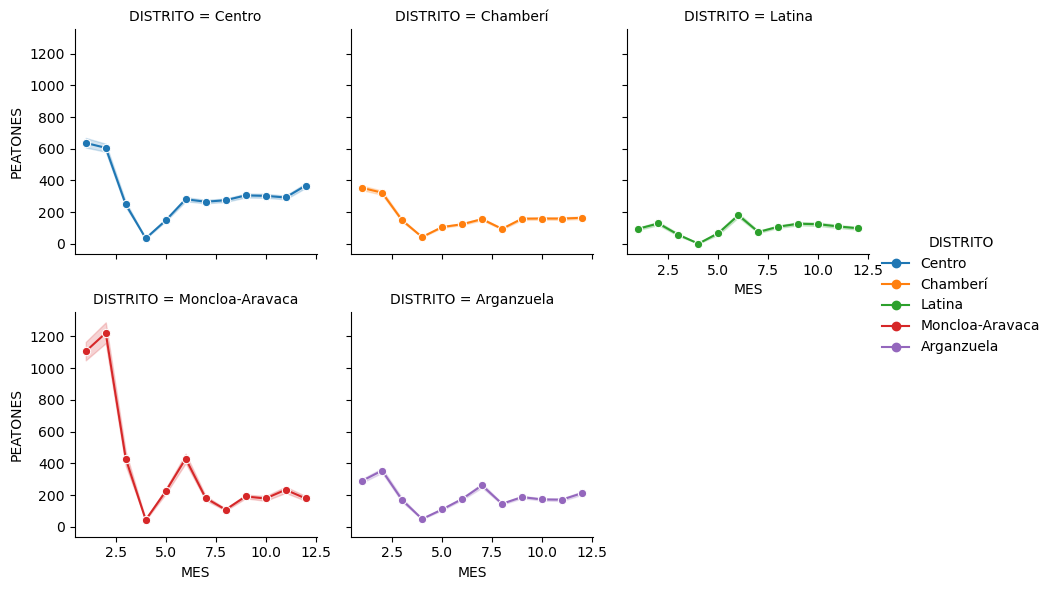

In [41]:
# Estudio de la evolución mensual de la media de peatones diferenciando los distritos.

import seaborn as sns

# Hacemos una columna nueva con el mes de cada observación
df_1["MES"] = df_1["FECHA"].dt.month

sns.relplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",    # Crea un panel por distrito
    col_wrap = 3,        # Coloca 3 gráficos por fila
    kind = "line",       # tipo de gráfico
    marker = "o",
    height = 3,          # Altura de cada panel
#    errorbar = None,      # intervalos de incertidumbre.
    hue = "DISTRITO"     # representa cada distrito con un color diferente.
)

plt.show()

</br>

Obtendremos un gráfico de puntos-líneas independiente para cada distrito. En concreto `line` hace:

- Agrupa internamente las observaciones de cada mes y distrito.
- Calcula la media de PEATONES.
- Representa las medias mediante puntos.
- Une los puntos mediante líneas.
- Muestra por defecto un intervalo de confianza del 95 %.
</br>


</br>

***scatter: Representa todas las lecturas individuales.***

</br>

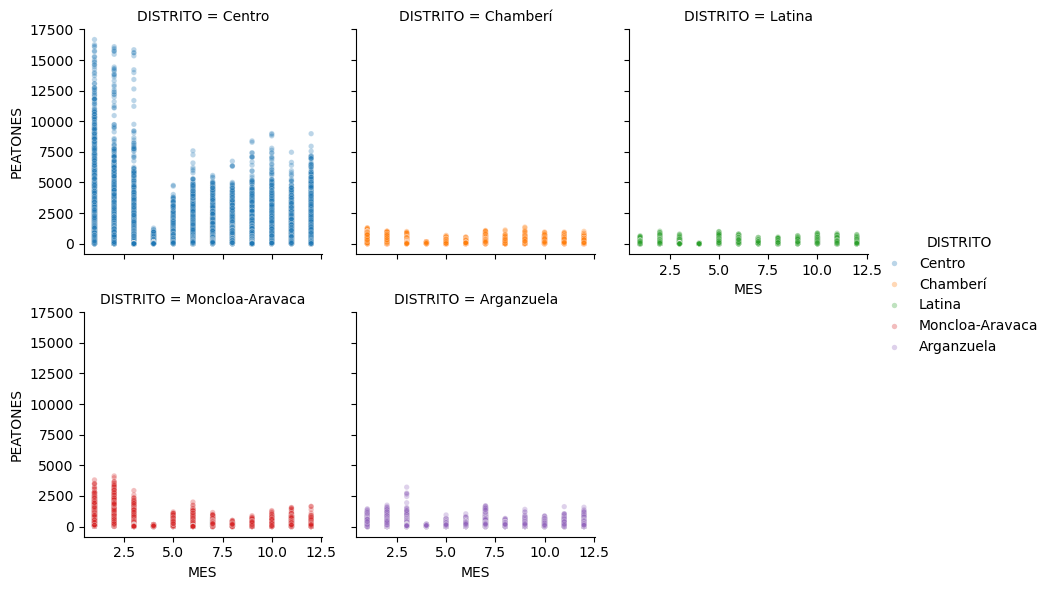

In [44]:
# Estudio mensual de todas las observaciones de peatones diferenciando los distritos.

import seaborn as sns

sns.relplot(
    data=df_1,
    x="MES",
    y="PEATONES",
    col="DISTRITO",
    kind="scatter",
    col_wrap=3,
    height=3,
    s=15,               # tamaño de los puntos
    alpha=0.3,          # transparencia
    hue = "DISTRITO"    # representa cada distrito con un color diferente.
)

plt.show()

</br>

***Observación:***


Fíjate que `sns.relplot(kind="line")` y `sns.relplot(kind="scatter")` no representan los datos de la misma manera cuando hay varias observaciones para un mismo mes y distrito. Esto es porque el gráfico de líneas calcula automáticamente la media de las observaciones, mientras que el gráfico de dispersión representa todas las observaciones individuales.


***En el gráfico de líneas***, Seaborn agrupa internamente las observaciones que tienen el mismo mes y distrito y calcula su media.
Por eso los mayores valores del gráfico de líneas están alrededor de 1.200, mientras que hay observaciones individuales que superan el valor 15.000.
Además, la banda sombreada que aparece alrededor de la línea representa el intervalo de confianza del 95%.

***En el gráfico de dispersión*** se representa cada fila del dataFrame como un punto. Por tanto, aparecen todas las lecturas individuales y el eje $y$ llega aproximadamente a 17.500, porque existen lecturas individuales de ese orden.

</br>

***Mejorar de la visualización***

Para mejorar la visualización vamos a guardar el `FacetGrid` en un objeto llamado, por ejemplo, `g`. 

Una vez creado `g`, recorremos todos los gráficos individuales (subplots) de la figura facetada con `g.axes.flat`. En concreto, `g.axes` contiene los ejes de los distintos gráficos y `.flat` convierte el recorrido de esa estructura en un recorrido lineal, de izquierda a derecha y de arriba abajo.

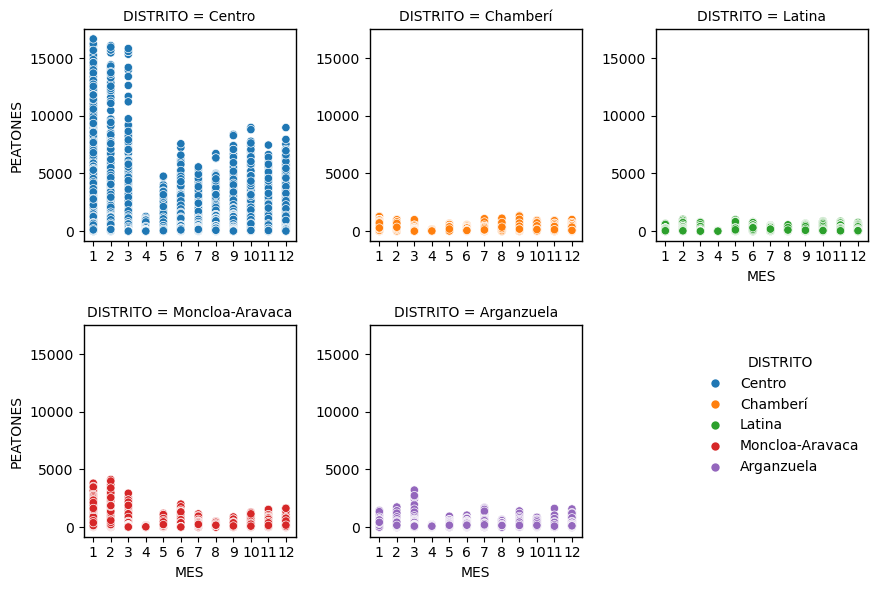

In [56]:
import seaborn as sns

# Hacemos una columna nueva con el mes de cada observación
df_1["MES"] = df_1["FECHA"].dt.month

g = sns.relplot(         # g es el objeto FacetGrid
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",    # Crea un panel por distrito
    col_wrap = 3,        # Coloca 3 gráficos por fila
    marker = "o",
    height = 3,          # Altura de cada panel
    #errorbar = None,     # intervalos de incertidumbre.
    hue = "DISTRITO"     # representa cada distrito con un color diferente.
)

g.figure.subplots_adjust(wspace=0.35, hspace=0.4)  # Control del espacio horizontal-vertical entre gráficas

# Mostrar los meses del 1 al 12 de todos los paneles de g (el sns anterior).
for ax in g.axes.flat:         # recoge cada gráfico individual en la variable ax
    
    ax.set_xticks(range(1, 13))                  # Mostrar los meses en todos los paneles
    ax.tick_params(axis="x", labelbottom=True)   # muestra todas las etiquetas del eje x
    ax.tick_params(axis="y", labelleft=True)     # Mostrar las etiquetas del eje Y

    # Dibujar un recuadro alrededor de cada gráfico
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1)
        spine.set_color("black")

# Mover la leyenda a la esquina inferior derecha
sns.move_legend(
    g,
    "center",                        # Sitúa el centro de la leyenda en la posición indicada 
    bbox_to_anchor=(0.75, 0.30),     # 0 (izquierda) a 1 (derecha). 0 (abajo) a 1 (arriba)
    title="DISTRITO"
)

plt.show()

### sns.catplot(): `kind="bar"` compara de medias y `kind="box"` compara distribución de las obs.

Se utiliza cuando queremos comparar una variable numérica entre diferentes categorías.

Puede representar diagramas de barras, cajas, violines y puntos, entre otros. Nosotros no vamo a centrar en los gráficos ya vistos.


| Función | `kind` | Nombre del gráfico | Comportamiento |
|---|---|---|---|
| `sns.catplot()` | `"bar"` | Gráfico de barras | Compara la media de una variable numérica entre categorías. |
| | `"box"` | Diagrama de caja | Compara distribuciones y medianas. |


</br>



</br>

***bar: comparar medias***


El gráfico de barras permite comparar la media mensual de los peatones entre distritos, 

***Observación***: `kind = "bar"` **muestra por defecto la media**, no la suma de los peatones. Si se quisiera mostrar la suma debo añadir el parámetro estimator="sum".

</br>


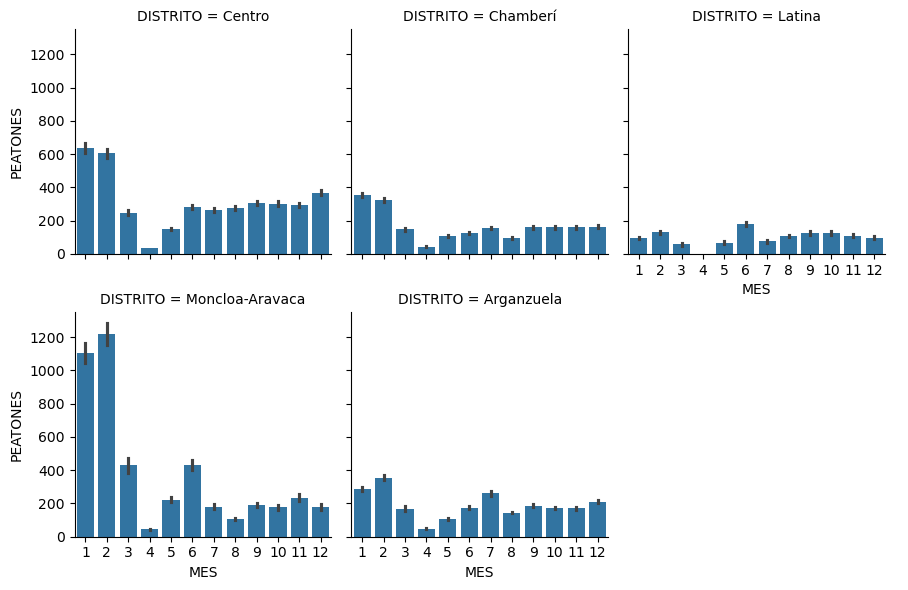

In [76]:

sns.catplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",
    kind = "bar",        # 	Media aritmética
    col_wrap = 3,
    height = 3,
    #estimator="sum"
)
   

plt.show()


Calcula la media de PEATONES para cada mes y distrito.

- Representa las medias mediante barras.
- Muestra intervalos de confianza del 95 % que son las pequeñas líneas verticales negras  situadas encima de cada barra. Se denominan barras de error (error bars).

</br>

</br>

***box: distribución de las lecturas***

</br>

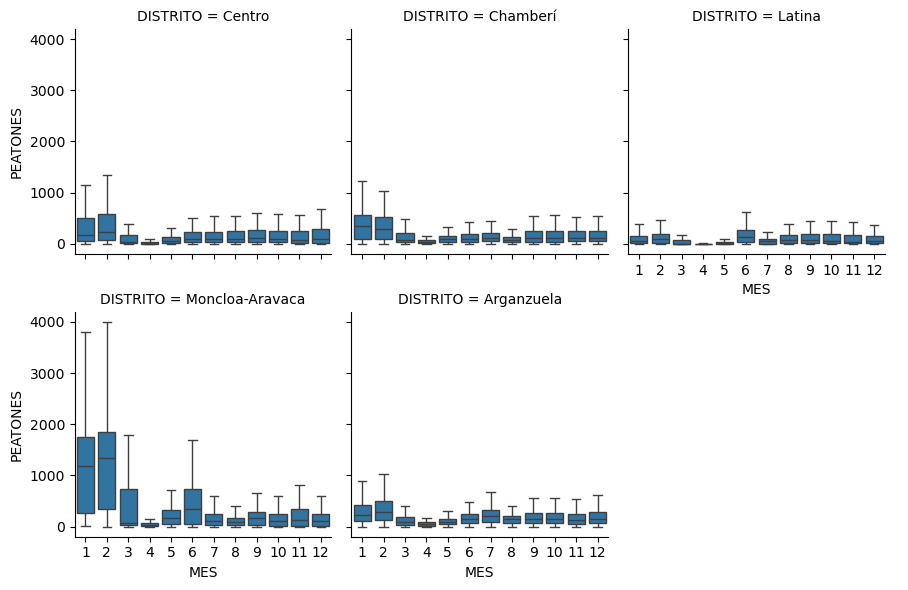

In [131]:
sns.catplot(
    data = df_1,
    x = "MES",
    y = "PEATONES",
    col = "DISTRITO",
    kind = "box",
    col_wrap = 3,
    showfliers = False,   # ocultar valores atípicos
    height = 3
)

plt.show()


El diagrama de cajas muestra la distribución de todas las lecturas de cada mes y distrito mediante:
- Mediana.
- Primer y tercer cuartil.
- Bigotes.
- Posibles valores atípicos (ocultos en este ejemplo).

El diagrama de cajas permite estudiar la variabilidad de los registros.



### sns.displot(): estudiar distribuciones

Se utiliza cuando queremos analizar cómo se distribuyen los valores de una variable numérica.


| Función | `kind` | Nombre del gráfico | Comportamiento |
|---|---|---|---|
| `sns.displot()` | `"hist"` | Histograma | Analiza la frecuencia de los valores de una variable numérica. |


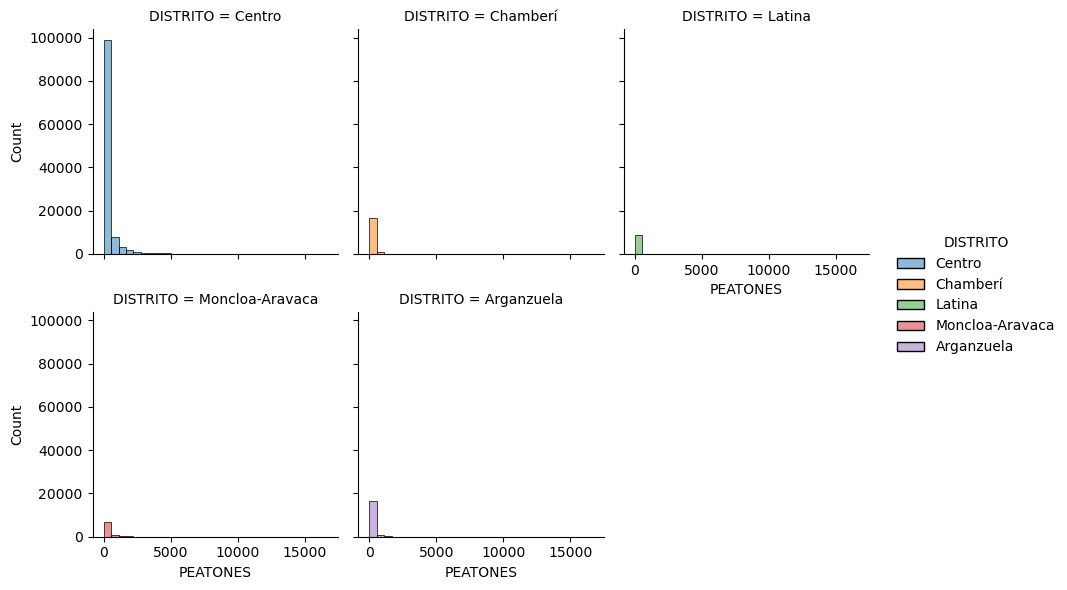

In [196]:
sns.displot(
    data=df_1,
    x="PEATONES",
    col="DISTRITO",
    col_wrap=3,
    kind="hist",
    bins=30,
    height=3,
    hue="DISTRITO"
)

plt.show()

# Conclusión


Elegimos `relplot` o `catplot` según qué queremos hacer con esos datos.
- Quiero observar la evolución de las medias → relplot(kind="line").
- Quiero ver todas las observaciones → relplot(kind="scatter").
- Quiero comparar medias mediante barras → catplot(kind="bar").
- Quiero estudiar la distribución y dispersión → catplot(kind="box").

| Gráfico | ¿Qué representa? | ¿Agrupa y resume los datos? |
|---|---|---|
| `relplot(kind="line")` | Media mensual mediante líneas | Sí, calcula la media. |
| `relplot(kind="scatter")` | Todas las lecturas individuales mediante puntos | No. |
| `catplot(kind="bar")` | Media mensual mediante barras | Sí, calcula la media. |
| `catplot(kind="box")` | Distribución mensual mediante cajas | Resume la distribución mediante cuartiles y bigotes. |
